In [6]:
!nvidia-smi

Wed Nov 25 04:05:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [7]:
!pip install -q ultralytics roboflow

In [8]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import os
import sys
import torch
import ultralytics
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/8vo semestre /Machine learning /PeajeInteligente")

os.makedirs(f"{BASE}/datasets", exist_ok=True)
os.makedirs(f"{BASE}/modelos", exist_ok=True)
os.makedirs(f"{BASE}/evidencias", exist_ok=True)
os.makedirs(f"{BASE}/notebooks", exist_ok=True)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
else:
    raise RuntimeError("Activa la GPU en Colab")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Ultralytics: 8.4.218
CUDA disponible: True
GPU: Tesla T4
CUDA: 13.0


In [10]:
modelo = YOLO("yolo11n-seg.pt")

print("Modelo cargado correctamente")
print(modelo.names)

Modelo cargado correctamente
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 

In [11]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="mPpeUiTYnUHN5sJRKg7H")
project = rf.workspace("adriana-ayllon").project("vehicle-classification-v2-dopil")
version = project.version(2)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...


In [12]:
from pathlib import Path
import yaml

DATASET_DIR = Path(dataset.location)
DATA_YAML = DATASET_DIR / "data.yaml"

assert DATA_YAML.exists(), "No se encontró data.yaml"

with open(DATA_YAML, "r") as f:
    config = yaml.safe_load(f)

print("Ubicación:", DATASET_DIR)
print("\nConfiguración del dataset:")
print(yaml.safe_dump(config, sort_keys=False))

print("\nCantidad de imágenes:")

for split in ["train", "valid", "test"]:
    carpeta = DATASET_DIR / split / "images"

    if carpeta.exists():
        imagenes = [
            p for p in carpeta.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

        print(f"{split}: {len(imagenes)} imágenes")

Ubicación: /content/Vehicle-Classification-V2-2

Configuración del dataset:
names:
- Ambulance
- Concrete Mixer
- Construction Equipment
- Cyclist
- Fire Truck
- Garbage Truck
- Pickup
- Pickup- Utility
- Tow Truck
- Tractor Trailer
- Trailer
- Van
- auto
- bus
- camion
- minibus
- moto
nc: 17
roboflow:
  license: CC BY 4.0
  project: vehicle-classification-v2-dopil
  url: https://universe.roboflow.com/adriana-ayllon/vehicle-classification-v2-dopil/dataset/2
  version: 2
  workspace: adriana-ayllon
test: ../test/images
train: ../train/images
val: ../valid/images


Cantidad de imágenes:
train: 2604 imágenes
valid: 736 imágenes
test: 367 imágenes


In [13]:
from collections import Counter

names = config["names"]

if isinstance(names, dict):
    names = [names[k] for k in sorted(names)]

print("CLASES DEL DATASET:")

for i, nombre in enumerate(names):
    print(f"{i}: {nombre}")

esperadas = {"auto", "moto", "minibus", "camion", "bus"}

actuales = {
    str(nombre).strip().lower()
    for nombre in names
}

conteo = Counter()
incorrectas = 0
total = 0

for archivo in DATASET_DIR.rglob("*.txt"):

    if archivo.parent.name != "labels":
        continue

    for linea in archivo.read_text().splitlines():

        if not linea.strip():
            continue

        valores = linea.split()
        total += 1

        try:
            clase = int(valores[0])
            puntos = list(map(float, valores[1:]))

            if (
                clase < 0
                or clase >= len(names)
                or len(puntos) < 6
                or len(puntos) % 2 != 0
                or any(p < 0 or p > 1 for p in puntos)
            ):
                incorrectas += 1
                continue

            conteo[clase] += 1

        except ValueError:
            incorrectas += 1

print("\nANOTACIONES POR CLASE:")

for i, nombre in enumerate(names):
    print(f"{nombre}: {conteo[i]}")

print("\nTotal de anotaciones:", total)
print("Anotaciones incorrectas:", incorrectas)
print("Clases faltantes:", esperadas - actuales)
print("Clases adicionales:", actuales - esperadas)

DATASET_OK = (
    actuales == esperadas
    and incorrectas == 0
    and total > 0
    and all(conteo[i] > 0 for i in range(len(names)))
)

print("\nDataset listo para entrenar:", DATASET_OK)

CLASES DEL DATASET:
0: Ambulance
1: Concrete Mixer
2: Construction Equipment
3: Cyclist
4: Fire Truck
5: Garbage Truck
6: Pickup
7: Pickup- Utility
8: Tow Truck
9: Tractor Trailer
10: Trailer
11: Van
12: auto
13: bus
14: camion
15: minibus
16: moto

ANOTACIONES POR CLASE:
Ambulance: 204
Concrete Mixer: 209
Construction Equipment: 138
Cyclist: 194
Fire Truck: 205
Garbage Truck: 126
Pickup: 293
Pickup- Utility: 71
Tow Truck: 59
Tractor Trailer: 192
Trailer: 157
Van: 231
auto: 1105
bus: 190
camion: 450
minibus: 197
moto: 212

Total de anotaciones: 4249
Anotaciones incorrectas: 16
Clases faltantes: set()
Clases adicionales: {'tow truck', 'fire truck', 'tractor trailer', 'construction equipment', 'garbage truck', 'van', 'ambulance', 'concrete mixer', 'cyclist', 'pickup', 'pickup- utility', 'trailer'}

Dataset listo para entrenar: False


In [14]:
import shutil
import yaml
import math
from pathlib import Path
from collections import Counter

ORIGINAL = Path(dataset.location)
LIMPIO = Path("/content/peaje_m2_limpio")

if LIMPIO.exists():
    shutil.rmtree(LIMPIO)

LIMPIO.mkdir(parents=True)

CLASES = ["auto", "bus", "camion", "minibus", "moto"]

MAPEO = {
    1: 2,    # Concrete Mixer -> camion
    4: 2,    # Fire Truck -> camion
    5: 2,    # Garbage Truck -> camion
    6: 0,    # Pickup -> auto
    7: 0,    # Pickup Utility -> auto
    8: 2,    # Tow Truck -> camion
    9: 2,    # Tractor Trailer -> camion
    12: 0,   # auto
    13: 1,   # bus
    14: 2,   # camion
    15: 3,   # minibus
    16: 4    # moto
}

conteo = Counter()
imagenes_guardadas = Counter()
descartadas = Counter()
conteo_split = {}

for split in ["train", "valid", "test"]:

    origen_img = ORIGINAL / split / "images"
    origen_lbl = ORIGINAL / split / "labels"

    if not origen_img.exists():
        continue

    destino_img = LIMPIO / split / "images"
    destino_lbl = LIMPIO / split / "labels"

    destino_img.mkdir(parents=True, exist_ok=True)
    destino_lbl.mkdir(parents=True, exist_ok=True)

    conteo_split[split] = Counter()

    for imagen in origen_img.iterdir():

        if imagen.suffix.lower() not in [
            ".jpg", ".jpeg", ".png", ".webp"
        ]:
            continue

        etiqueta = origen_lbl / f"{imagen.stem}.txt"

        if not etiqueta.exists():
            descartadas[split] += 1
            continue

        nuevas_lineas = []
        clases_imagen = []
        valida = True

        for linea in etiqueta.read_text().splitlines():

            if not linea.strip():
                continue

            valores = linea.split()

            try:
                clase = int(valores[0])
                puntos = list(map(float, valores[1:]))

                if (
                    clase not in MAPEO
                    or len(puntos) < 6
                    or len(puntos) % 2 != 0
                    or any(
                        not math.isfinite(p) or p < 0 or p > 1
                        for p in puntos
                    )
                ):
                    valida = False
                    break

                nueva_clase = MAPEO[clase]

                nueva_linea = (
                    str(nueva_clase)
                    + " "
                    + " ".join(valores[1:])
                )

                nuevas_lineas.append(nueva_linea)
                clases_imagen.append(nueva_clase)

            except (ValueError, IndexError):
                valida = False
                break

        if not valida or not nuevas_lineas:
            descartadas[split] += 1
            continue

        shutil.copy2(imagen, destino_img / imagen.name)

        (destino_lbl / etiqueta.name).write_text(
            "\n".join(nuevas_lineas) + "\n"
        )

        conteo.update(clases_imagen)
        conteo_split[split].update(clases_imagen)
        imagenes_guardadas[split] += 1

config_limpia = {
    "path": str(LIMPIO),
    "train": "train/images",
    "val": "valid/images",
    "nc": 5,
    "names": CLASES
}

if imagenes_guardadas["test"] > 0:
    config_limpia["test"] = "test/images"

DATA_YAML = LIMPIO / "data.yaml"

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(config_limpia, f, sort_keys=False)

print("=" * 50)
print("DATASET CORREGIDO")
print("=" * 50)

for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()}")
    print("Imágenes:", imagenes_guardadas[split])
    print("Descartadas:", descartadas[split])

    for i, nombre in enumerate(CLASES):
        print(f"  {nombre}: {conteo_split.get(split, {}).get(i, 0)}")

print("\nTOTAL DE ANOTACIONES POR CLASE:")

for i, nombre in enumerate(CLASES):
    print(f"{nombre}: {conteo[i]}")

DATASET_DIR = LIMPIO

DATASET_OK = all(
    conteo_split.get(split, {}).get(i, 0) > 0
    for split in ["train", "valid"]
    for i in range(5)
)

print("\nRuta YAML:", DATA_YAML)
print("Dataset listo para entrenar:", DATASET_OK)

DATASET CORREGIDO

TRAIN
Imágenes: 2015
Descartadas: 589
  auto: 955
  bus: 126
  camion: 828
  minibus: 131
  moto: 147

VALID
Imágenes: 572
Descartadas: 164
  auto: 267
  bus: 32
  camion: 241
  minibus: 36
  moto: 37

TEST
Imágenes: 288
Descartadas: 79
  auto: 141
  bus: 22
  camion: 108
  minibus: 11
  moto: 18

TOTAL DE ANOTACIONES POR CLASE:
auto: 1363
bus: 180
camion: 1177
minibus: 178
moto: 202

Ruta YAML: /content/peaje_m2_limpio/data.yaml
Dataset listo para entrenar: True


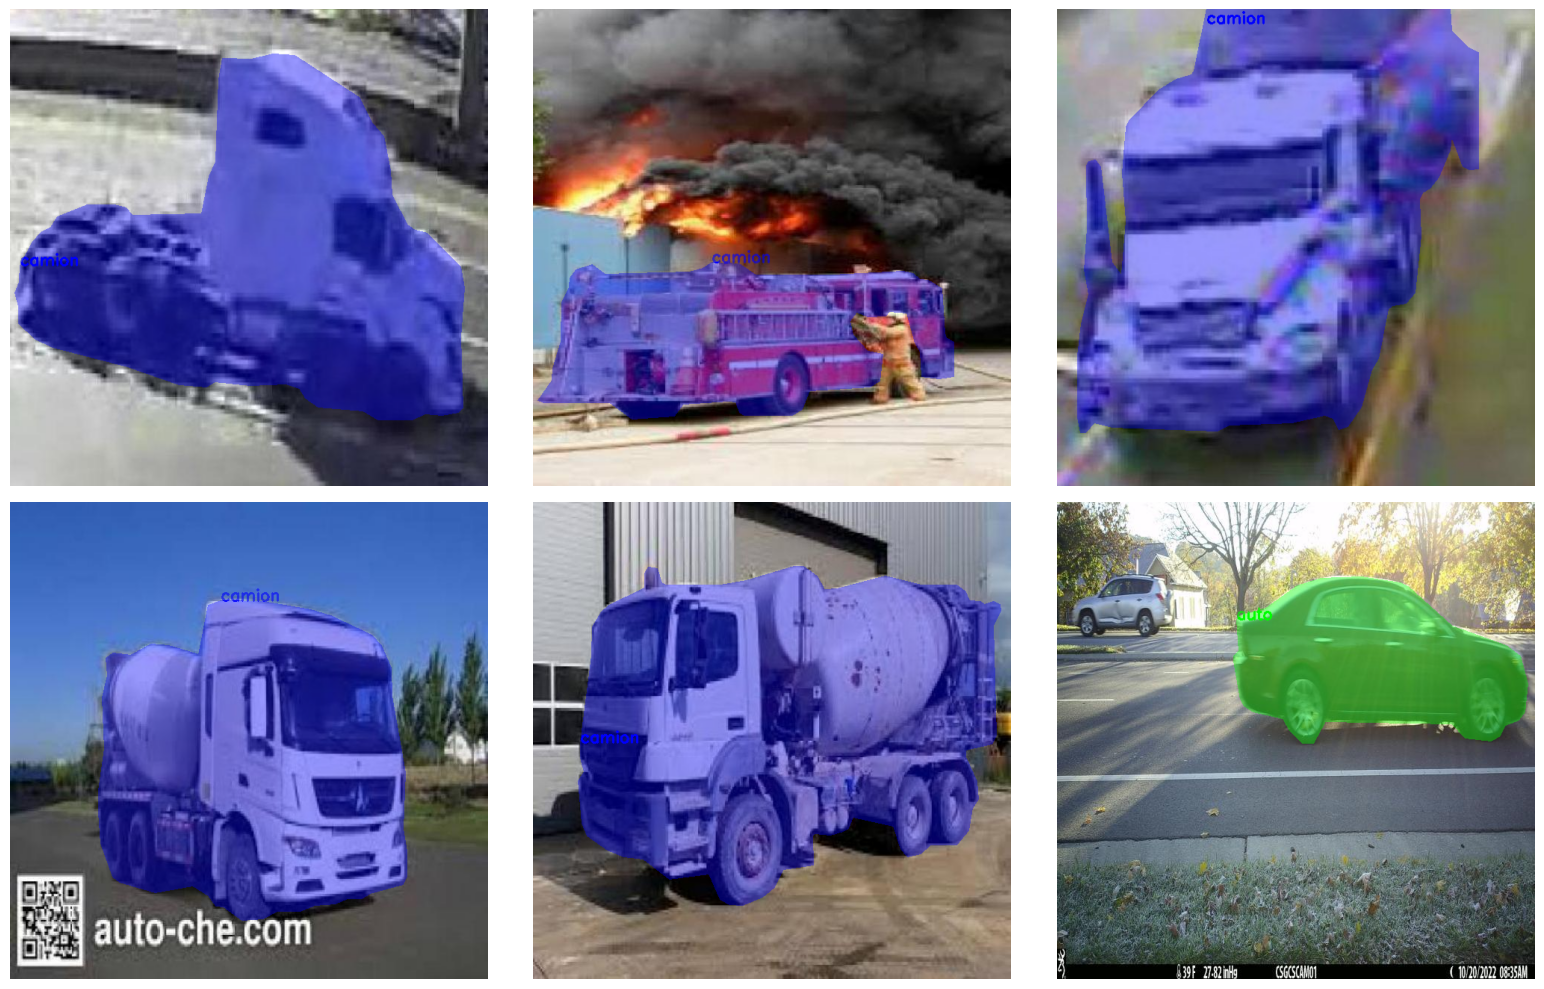

In [15]:
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt

carpeta = DATASET_DIR / "train" / "images"

imagenes = list(carpeta.iterdir())

colores = [
    (0, 255, 0),
    (255, 0, 0),
    (0, 0, 255),
    (255, 255, 0),
    (255, 0, 255)
]

seleccion = random.sample(
    imagenes,
    min(6, len(imagenes))
)

plt.figure(figsize=(16, 10))

for i, archivo in enumerate(seleccion):

    imagen = cv2.imread(str(archivo))
    imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    h, w = imagen.shape[:2]

    etiqueta = (
        DATASET_DIR / "train" / "labels"
        / f"{archivo.stem}.txt"
    )

    overlay = imagen.copy()

    for linea in etiqueta.read_text().splitlines():

        valores = linea.split()
        clase = int(valores[0])

        puntos = np.array(
            list(map(float, valores[1:]))
        ).reshape(-1, 2)

        puntos[:, 0] *= w
        puntos[:, 1] *= h

        puntos = puntos.astype(np.int32)

        cv2.fillPoly(
            overlay,
            [puntos],
            colores[clase]
        )

        x, y = puntos[0]

        cv2.putText(
            imagen,
            CLASES[clase],
            (x, max(y, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            colores[clase],
            2
        )

    imagen = cv2.addWeighted(
        imagen, 0.6,
        overlay, 0.4,
        0
    )

    plt.subplot(2, 3, i + 1)
    plt.imshow(imagen)
    plt.axis("off")

plt.tight_layout()
plt.savefig(
    f"{BASE}/evidencias/dataset_M2.png",
    dpi=150
)
plt.show()

In [16]:
from ultralytics import YOLO
import torch

assert DATASET_OK, "El dataset todavía no está listo"
assert torch.cuda.is_available(), "Activa la GPU"

modelo_m2 = YOLO("yolo11n-seg.pt")

resultados_m2 = modelo_m2.train(
    data=str(DATA_YAML),
    epochs=15,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=5,
    project=f"{BASE}/modelos",
    name="M2_vehiculos",
    exist_ok=True,
    pretrained=True,
    plots=True,
    save=True,
    save_period=1,
    amp=True,
    seed=42
)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/peaje_m2_limpio/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=M2_vehiculos, nbs=64, nms=None, opset=None, optimi

In [20]:
from pathlib import Path
import shutil

ORIGEN = Path(
    "/content/drive/MyDrive/8vo semestre/Machine learning/PeajeInteligente"
)

# IMPORTANTE: conservar los espacios al final
DESTINO = Path(
    "/content/drive/MyDrive/8vo semestre /Machine learning /PeajeInteligente"
)

assert ORIGEN.is_dir(), "No existe la carpeta de origen"
assert DESTINO.is_dir(), "No existe la carpeta correcta"

shutil.copytree(
    ORIGEN,
    DESTINO,
    dirs_exist_ok=True
)

BASE = DESTINO

BEST_M2 = BASE / "modelos/M2_vehiculos/weights/best.pt"

assert BEST_M2.exists(), "No se encontró el modelo"

print("Archivos copiados correctamente")
print("Ruta:", BEST_M2)
print("Tamaño:", round(BEST_M2.stat().st_size / 1024**2, 2), "MB")

Archivos copiados correctamente
Ruta: /content/drive/MyDrive/8vo semestre /Machine learning /PeajeInteligente/modelos/M2_vehiculos/weights/best.pt
Tamaño: 5.75 MB


In [21]:
for archivo in (BASE / "modelos/M2_vehiculos").rglob("*"):
    if archivo.is_file():
        print(archivo.relative_to(BASE))

modelos/M2_vehiculos/args.yaml
modelos/M2_vehiculos/labels.jpg
modelos/M2_vehiculos/train_batch0.jpg
modelos/M2_vehiculos/train_batch1.jpg
modelos/M2_vehiculos/train_batch2.jpg
modelos/M2_vehiculos/results.csv
modelos/M2_vehiculos/train_batch630.jpg
modelos/M2_vehiculos/train_batch631.jpg
modelos/M2_vehiculos/train_batch632.jpg
modelos/M2_vehiculos/val_batch0_labels.jpg
modelos/M2_vehiculos/val_batch0_pred.jpg
modelos/M2_vehiculos/val_batch1_pred.jpg
modelos/M2_vehiculos/val_batch1_labels.jpg
modelos/M2_vehiculos/val_batch2_labels.jpg
modelos/M2_vehiculos/val_batch2_pred.jpg
modelos/M2_vehiculos/BoxPR_curve.png
modelos/M2_vehiculos/BoxF1_curve.png
modelos/M2_vehiculos/BoxP_curve.png
modelos/M2_vehiculos/BoxR_curve.png
modelos/M2_vehiculos/MaskPR_curve.png
modelos/M2_vehiculos/MaskF1_curve.png
modelos/M2_vehiculos/MaskP_curve.png
modelos/M2_vehiculos/MaskR_curve.png
modelos/M2_vehiculos/confusion_matrix_normalized.png
modelos/M2_vehiculos/confusion_matrix.png
modelos/M2_vehiculos/result

In [19]:
import os

for semestre in os.listdir("/content/drive/MyDrive"):
    if "8vo" in semestre.lower():
        print("SEMESTRE:", repr(semestre))

        ruta = os.path.join("/content/drive/MyDrive", semestre)

        if os.path.isdir(ruta):
            for carpeta in os.listdir(ruta):
                if "machine" in carpeta.lower():
                    print("MATERIA:", repr(carpeta))

                    materia = os.path.join(ruta, carpeta)

                    print("RUTA:", repr(materia))
                    print("CONTENIDO:", os.listdir(materia))
                    print("-" * 60)

SEMESTRE: 'IA 8VO'
SEMESTRE: '8vo semestre '
MATERIA: 'Machine learning '
RUTA: '/content/drive/MyDrive/8vo semestre /Machine learning '
CONTENIDO: ['PeajeInteligente', 'Ayllón_Pardo_Adriana_LAB1H2', 'video colab', 'video runpod', 'AYLLON_PARDO_ADRIANA']
------------------------------------------------------------
SEMESTRE: '8vo semestre'
MATERIA: 'Machine learning'
RUTA: '/content/drive/MyDrive/8vo semestre/Machine learning'
CONTENIDO: ['PeajeInteligente']
------------------------------------------------------------
